# 2 · Values, prices of production and the wage–profit frontier

With a technical matrix `A` (`A[i,j]` is the input of good `i` per unit of good `j`) and direct labor coefficients `l`:

- **Labor values** solve `λ = Aᵀλ + l`, so `λ = (I − Aᵀ)⁻¹ l`.
- **Prices of production** (Sraffa) at a uniform rate of profit `r̄` and wage `w`: `p = w(1 + r̄)[I − (1 + r̄)Aᵀ]⁻¹ l`.
- The **maximum rate of profit** `R = 1/ρ(A) − 1` is reached when wages are zero.

This notebook computes them, traces the wage–profit frontier, and runs the library's transformation-problem analysis.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, Random, LinearAlgebra
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

## 1. A technical matrix and labor values

`create_technical_matrix` draws a sparse random matrix and always rescales it to a spectral radius below 1, so the economy is productive.

In [2]:
N = 5
A = create_technical_matrix(N, seed = 3)
l = [0.5, 0.4, 0.3, 0.6, 0.45]
λ = compute_labor_values(A, l)
R = compute_max_profit_rate(A, l)
(ρ_A = maximum(abs.(eigvals(A))), R_max = R, λ = λ)

(ρ_A = 0.13995107873308574, R_max = 6.145353998358218, λ = [0.5688880307963979, 0.4, 0.34881736675871683, 0.6575550449870615, 0.45])

## 2. Prices of production diverge from values

At `r̄ = 0` prices are proportional to values. As the rate of profit rises, relative prices move away from values: the direction for each sector depends on how much means of production it uses, directly and indirectly, per unit of labor. Below, prices are normalized so that their sum equals the sum of values.

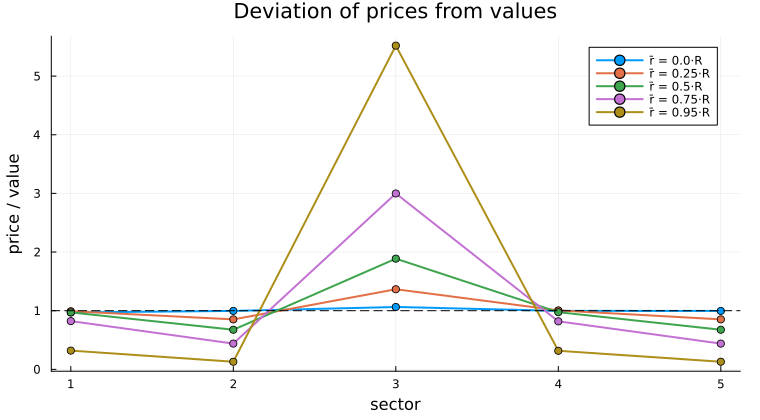

In [3]:
fractions = [0.0, 0.25, 0.5, 0.75, 0.95]
ratios = map(fractions) do f
    pr = compute_production_prices(A, l, 1.0, f * R)
    (pr .* sum(λ) ./ sum(pr)) ./ λ
end
plot(1:N, hcat(ratios...), marker = :circle, lw = 2,
     label = permutedims(["r̄ = $(f)·R" for f in fractions]),
     xlabel = "sector", ylabel = "price / value", title = "Deviation of prices from values")
hline!([1.0], color = :black, ls = :dash, label = "")

## 3. The wage–profit frontier

`wage_profit_curve` traces `w(r)` from `r = 0` (all net product to wages) to `r = R` (zero wage), with the price vector at each point. With `show_plot = true` it also draws a four-panel figure; here we draw the frontier ourselves.

FRONTIER OF DISTRIBUTIONAL POSSIBILITIES

Maximum profit rate (w=0): 614.54%
Maximum wage (r=0): 1.8046
Mean elasticity ε(w,r): -1.252


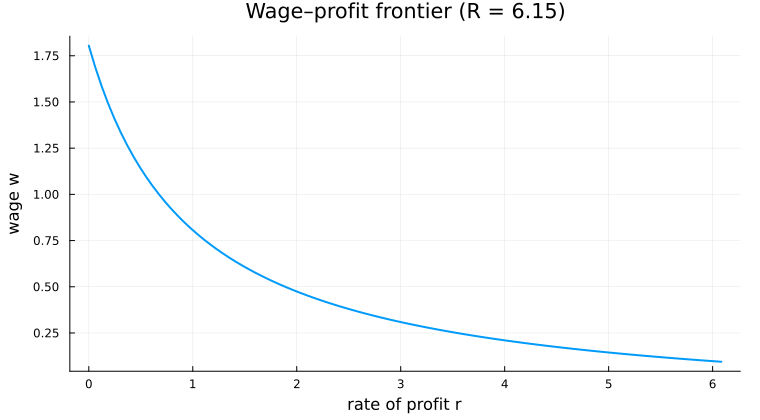

In [4]:
fr = wage_profit_curve(A, l; show_plot = false)
plot(fr.r, fr.w, lw = 2, legend = false, xlabel = "rate of profit r",
     ylabel = "wage w", title = "Wage–profit frontier (R = $(round(fr.R_max, digits = 2)))")

The frontier is a straight line only in special cases (e.g. equal organic compositions). `frontier_curvature` gives `w(r)`, `w′(r)` and `w″(r)` exactly, by automatic differentiation, and classifies its shape. The curvature can change sign along the frontier.

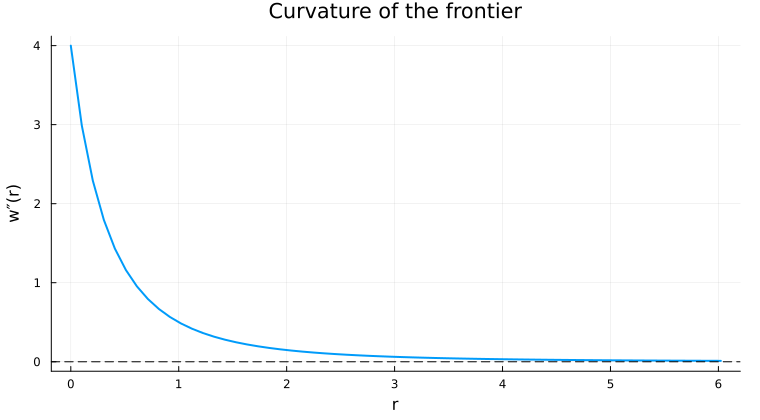

In [5]:
rs = range(0, 0.98R, length = 60)
c = [frontier_curvature(A, l, r) for r in rs]
plot(rs, getfield.(c, :d2w), lw = 2, legend = false, xlabel = "r", ylabel = "w″(r)",
     title = "Curvature of the frontier")
hline!([0.0], color = :black, ls = :dash)

In [6]:
frontier_curvature(A, l, 0.2)

(w = 1.4716770462894426, dw = -1.3870900896183094, d2w = 2.3144973287103237, shape = :convex)

## 4. The transformation problem

`transformation_problem(N)` builds a random economy (from the global random number generator) and computes prices of production at several rates of profit, normalized to sum to one like the values. It prints the percentage deviations of prices from values and draws a four-panel figure for `r̄ = 0.3`: values against prices, the deviations, the mean absolute deviation as `r̄` rises, and the value–price correlation.

TRANSFORMATION OF VALUES INTO PRICES

Maximum profit rate: 378.6%

Technical Matrix A:


5×5 Matrix{Float64}:
 0.052  0.0    0.0    0.0    0.116
 0.0    0.0    0.086  0.045  0.085
 0.0    0.002  0.017  0.0    0.0
 0.127  0.135  0.13   0.0    0.0
 0.062  0.0    0.0    0.117  0.066



Labor Values λ (normalized):


5-element Vector{Float64}:
 0.1358
 0.2452
 0.17
 0.2162
 0.2329



Analysis by Profit Rate:
----------------------------------------------------------------------

r̄ = 0.0%
Deviations (%): 

[8.02, -8.17, 25.04, -16.35, 0.82]

r̄ = 10.0%
Deviations (%): [9.55, -9.26, 25.12, -16.35, 1.02]

r̄ = 20.0%
Deviations (%): [11.09, -10.35, 25.17, -16.35, 1.24]

r̄ = 30.0%
Deviations (%): [12.66, -11.44, 25.19, -16.35, 1.46]

r̄ = 40.0%
Deviations (%): [14.25, -12.53, 25.18, -16.36, 1.69]


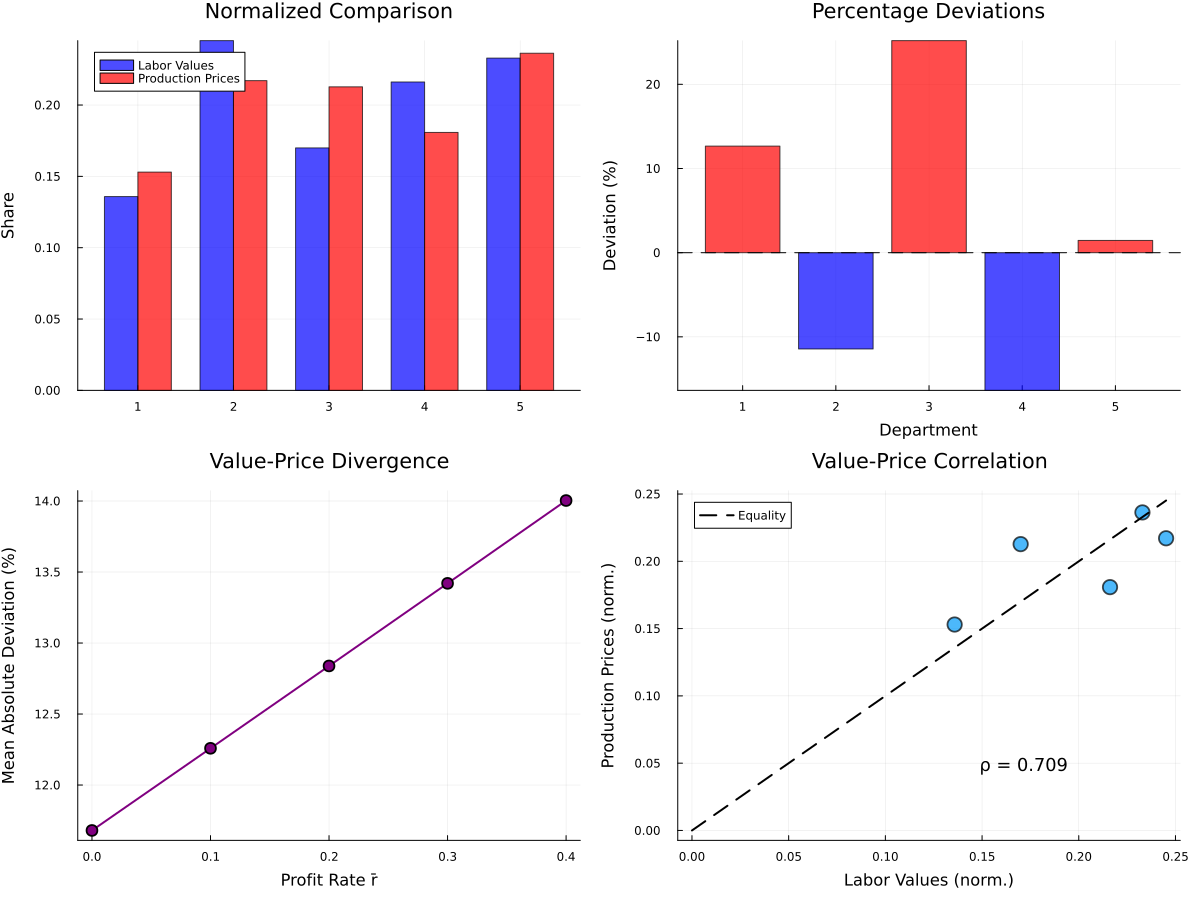

In [7]:
Random.seed!(1)
tp = transformation_problem(5);

In [8]:
(R_max = tp.R_max, value_price_correlation = tp.correlation)

(R_max = 3.7858522294438055, value_price_correlation = 0.7093997423910104)